
# Business Case

Google Play has over 3 million applications and billions of downloads every year. However, many apps fail to gain users, receive poor ratings, or disappear shortly after launch.

Before investing in new marketplace initiatives, Google wants to understand:

- What makes an app successful?
- Which categories deserve investment?
- Which developer behaviors lead to better user satisfaction?
- How can Google improve the ecosystem for both users and developers?






## Understanding Data

In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical Analysis
from scipy import stats

df = pd.read_csv("/content/googleplaystore.csv")

In [2]:
# Create a backup copy
df_original = df.copy()

In [3]:
print("Dimension of dataset: ",df.shape)
print("Memory Usage (MB): ", df.memory_usage().sum()/1024**2)

Dimension of dataset:  (10841, 13)
Memory Usage (MB):  1.0753593444824219


In [4]:
df.sample(6)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
8259,Batman: Gotham’s Most Wanted!,FAMILY,4.0,16190,88M,"1,000,000+",Free,0,Everyone,Action;Action & Adventure,"April 24, 2018",2.1.1,4.0 and up
4122,LINE: Free Calls & Messages,COMMUNICATION,4.2,10790092,Varies with device,"500,000,000+",Free,0,Everyone,Communication,"July 26, 2018",Varies with device,Varies with device
989,Kidjo TV Kids Have Fun & Learn,ENTERTAINMENT,4.6,732,Varies with device,"100,000+",Free,0,Everyone,Entertainment;Music & Video,"August 1, 2018",Varies with device,Varies with device
10615,Alachua County Sheriff FL,LIFESTYLE,3.2,5,9.5M,100+,Free,0,Everyone,Lifestyle,"May 13, 2015",1.0,4.0 and up
4933,AC Remote For LG,TOOLS,3.0,1298,3.4M,"100,000+",Free,0,Everyone,Tools,"February 20, 2018",1.0,4.0 and up
6956,QR & Barcode Scanner BX PRO,TOOLS,NaN,4,3.0M,"1,000+",Free,0,Everyone,Tools,"October 30, 2017",1.0,4.2 and up


## Data Quality Audit:

- Completeness:	Is any important data missing?
- Validity:	Is the data stored in the correct format?
- Consistency:	Is similar information represented consistently?
- Uniqueness:	Are duplicate records present?
- Accuracy:	Does the data appear realistic?

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [6]:
# Missing Value Analysis

missing = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

missing_percent = (
    round(
        missing/len(df)*100,
        2
    )
)

missing_df = pd.DataFrame({
    "Missing Count":missing,
    "Missing %":missing_percent
})

missing_df

,Missing Count,Missing %
Rating,1474,13.60
Current Ver,8,0.07
Android Ver,3,0.03
Content Rating,1,0.01
Type,1,0.01
Size,0,0.00
Reviews,0,0.00
Category,0,0.00
App,0,0.00
Price,0,0.00


Approximately 13.6% of apps have no rating. This is expected because new or unpopular apps may not have received sufficient user feedback.

In [7]:
# Duplicate Analysis

# Are we counting the same app multiple times?

duplicate_rows = df.duplicated().sum()

print("Duplicate Rows:",duplicate_rows)

Duplicate Rows: 483


In [8]:
duplicates = df[df.duplicated()]

duplicates.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
229,Quick PDF Scanner + OCR FREE,BUSINESS,4.2,80805,Varies with device,"5,000,000+",Free,0,Everyone,Business,"February 26, 2018",Varies with device,4.0.3 and up
236,Box,BUSINESS,4.2,159872,Varies with device,"10,000,000+",Free,0,Everyone,Business,"July 31, 2018",Varies with device,Varies with device
239,Google My Business,BUSINESS,4.4,70991,Varies with device,"5,000,000+",Free,0,Everyone,Business,"July 24, 2018",2.19.0.204537701,4.4 and up
256,ZOOM Cloud Meetings,BUSINESS,4.4,31614,37M,"10,000,000+",Free,0,Everyone,Business,"July 20, 2018",4.1.28165.0716,4.0 and up
261,join.me - Simple Meetings,BUSINESS,4.0,6989,Varies with device,"1,000,000+",Free,0,Everyone,Business,"July 16, 2018",4.3.0.508,4.4 and up


## Data Type Audit

In [9]:
dtype_df = pd.DataFrame({
    "Column":df.columns,
    "Current Type":df.dtypes.values
})

dtype_df

,Column,Current Type
0,App,object
1,Category,object
2,Rating,float64
3,Reviews,object
4,Size,object
5,Installs,object
6,Type,object
7,Price,object
8,Content Rating,object
9,Genres,object


Expected data type of columns differ from current data type.
Data type issues prevent meaningful analysis.

##  Cardinality Analysis

In [10]:
cardinality = pd.DataFrame({
    "Unique Values":df.nunique()
}).sort_values(
    by="Unique Values",
    ascending=False
)

cardinality

,Unique Values
App,9660
Reviews,6002
Current Ver,2832
Last Updated,1378
Size,462
Genres,120
Price,93
Rating,40
Category,34
Android Ver,33


Influences Encoding,
Visualization,
Statistical tests

In [11]:
# Inspect Categorical Variables

categorical_cols = df.select_dtypes(
    include="object"
).columns

for col in categorical_cols:

    print("\n")
    print("="*60)

    print(col)

    print("="*60)

    print(df[col].value_counts().head(10))



App
App
ROBLOX                                               9
CBS Sports App - Scores, News, Stats & Watch Live    8
8 Ball Pool                                          7
Candy Crush Saga                                     7
ESPN                                                 7
Duolingo: Learn Languages Free                       7
Temple Run 2                                         6
Bowmasters                                           6
Helix Jump                                           6
Nick                                                 6
Name: count, dtype: int64


Category
Category
FAMILY             1972
GAME               1144
TOOLS               843
MEDICAL             463
BUSINESS            460
PRODUCTIVITY        424
PERSONALIZATION     392
COMMUNICATION       387
SPORTS              384
LIFESTYLE           382
Name: count, dtype: int64


Reviews
Reviews
0    596
1    272
2    214
3    175
4    137
5    108
6     97
7     90
8     74
9     65
Name: count, dtype: 

In [12]:
df.describe()

,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


In [13]:
## Business Data Validation
# Ratings should be between 0 and 5

invalid_rating = df[
    (df["Rating"]<0) |
    (df["Rating"]>5)
]

print(invalid_rating.shape)

(1, 13)


In [14]:
# Price should never be negative.

invalid_price = df[
    df["Price"].str.contains("-")
]

invalid_price

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [15]:
# Type should only contain Free, Paid

df["Type"].unique()

array(['Free', 'Paid', nan, '0'], dtype=object)

## Data Quality Report:



In [16]:
quality_report = pd.DataFrame({
    "Quality Dimension": [
        "Completeness",
        "Uniqueness",
        "Validity",
        "Consistency"
    ],
    "Status": [
        "Needs Review",
        "Needs Validation",
        "Needs Cleaning",
        "Needs Cleaning"
    ],
    "Comments": [
        "Missing ratings and version information detected.",
        "Duplicate records require investigation.",
        "Incorrect data types for multiple columns.",
        "Formatting inconsistencies in numeric fields."
    ]
})

quality_report

,Quality Dimension,Status,Comments
0,Completeness,Needs Review,Missing ratings and version information detected.
1,Uniqueness,Needs Validation,Duplicate records require investigation.
2,Validity,Needs Cleaning,Incorrect data types for multiple columns.
3,Consistency,Needs Cleaning,Formatting inconsistencies in numeric fields.


# Data cleaning and Data Preparation

In [17]:
# Review stored as text, convert to integer

df["Reviews"] = pd.to_numeric(
    df["Reviews"],
    errors="coerce"
)

In [18]:
# Validate

df['Reviews'].dtype

dtype('float64')

In [19]:
# Installs stored as "1,000+", Remove commas and +

df["Installs"] = (
    df["Installs"]
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

In [20]:
df["Installs"] = pd.to_numeric(
    df["Installs"],
    errors="coerce"
)

In [21]:
# Validate

df['Installs'].sample(3)

,Installs
10533,10.0
91,1000000.0
332,50000.0


In [22]:
# Price contains $, remove $ and convert data type

df["Price"] = (
    df["Price"]
    .str.replace("$","",regex=False)
)

df["Price"] = pd.to_numeric(
    df["Price"],
    errors="coerce"
)

In [23]:
# Size stored as "14M", "512k" and 'Varies with device', convert everything into 'MB'

# Replace invalid value
df["Size"] = df["Size"].replace(
    "Varies with device",
    np.nan
)

# Create conversion function:

def convert_size(size):

    if pd.isna(size):
        return np.nan

    if size.endswith("M"):
        return float(size[:-1])

    elif size.endswith("k"):
        return float(size[:-1])/1024

    else:
        return np.nan



df["Size_MB"] = df["Size"].apply(
    convert_size
)



In [24]:
df["Size_MB"] = pd.to_numeric(
    df["Size_MB"],
    errors="coerce"
)

In [25]:
df.drop(columns='Size',inplace=True)

In [26]:
# Change 'Last Updated' Column data type from object to datetime

df["Last Updated"] = pd.to_datetime(
    df["Last Updated"]
)

ValueError: time data "1.0.19" doesn't match format "%B %d, %Y", at position 1348. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

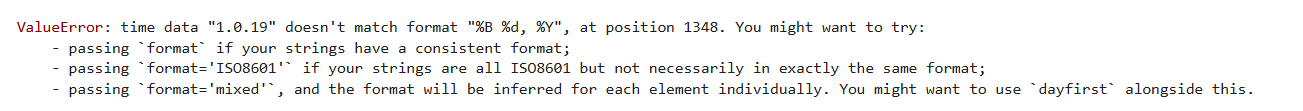

This means that Pandas expected something like: April 2, 2018 but found 1.0.19

In Actual, 1.0.19 looks like a Current Version, not a date.

This means the columns in that row are shifted.

In [27]:
# Finding the corrupted row

df[df["Last Updated"] == "1.0.19"]

,App,Category,Rating,Reviews,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,NaN,NaN,0,NaN,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN,NaN


In [28]:
# Remove this corrupted row

df = df[df["Category"] != "1.9"]

In [29]:
# Retry datatype conversion

df["Last Updated"] = pd.to_datetime(
    df["Last Updated"],
    errors="coerce"
)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10840 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             10840 non-null  object        
 1   Category        10840 non-null  object        
 2   Rating          9366 non-null   float64       
 3   Reviews         10840 non-null  float64       
 4   Installs        10840 non-null  float64       
 5   Type            10839 non-null  object        
 6   Price           10840 non-null  float64       
 7   Content Rating  10840 non-null  object        
 8   Genres          10840 non-null  object        
 9   Last Updated    10840 non-null  datetime64[ns]
 10  Current Ver     10832 non-null  object        
 11  Android Ver     10838 non-null  object        
 12  Size_MB         9145 non-null   float64       
dtypes: datetime64[ns](1), float64(5), object(7)
memory usage: 1.2+ MB


#  Business  Rule Validation

In [31]:
assert df["Rating"].dropna().between(0,5).all()

print("✅ Ratings validated successfully.")

✅ Ratings validated successfully.


In [32]:
assert (df["Installs"] >= 0).all()
print("✅ Installs validated successfully.")

assert (df["Reviews"] >= 0).all()
print("✅ Reviews validated successfully.")

assert (df["Price"] >= 0).all()
print("✅ Price validated successfully.")

✅ Installs validated successfully.
✅ Reviews validated successfully.
✅ Price validated successfully.


# EDA

**1. Marketplace Overview**

What does the Google Play ecosystem look like?

In [33]:
total_apps = len(df)

total_categories = df["Category"].nunique()

avg_rating = round(df["Rating"].mean(),2)

total_installs = df["Installs"].sum()

free_apps = (df["Type"]=="Free").sum()

paid_apps = (df["Type"]=="Paid").sum()

print(f"Total Apps          : {total_apps:,}")
print(f"Categories          : {total_categories}")
print(f"Average Rating      : {avg_rating}")
print(f"Total Installs      : {total_installs:,}")
print(f"Free Apps           : {free_apps:,}")
print(f"Paid Apps           : {paid_apps:,}")

Total Apps          : 10,840
Categories          : 33
Average Rating      : 4.19
Total Installs      : 167,633,433,487.0
Free Apps           : 10,039
Paid Apps           : 800


**2.  User Satisfaction Analysis**


Are users generally satisfied with apps?

In [34]:
# Descriptive Statistics on 'Rating' Column:

df["Rating"].describe()

,Rating
count,9366.000000
mean,4.191757
std,0.515219
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,5.000000


In [35]:
df["Rating"].skew()

np.float64(-1.8496951283704521)

Text(0, 0.5, 'Frequency')

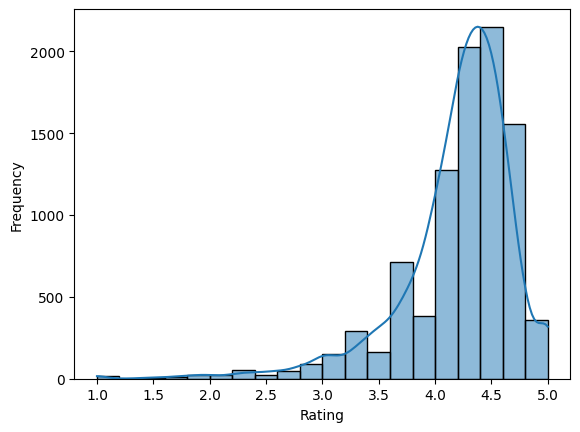

In [36]:
sns.histplot(df["Rating"], bins=20, kde=True)
plt.xlabel("Rating")
plt.ylabel("Frequency")

Indicates presence of More highly-rated apps.

In [37]:
df["Rating"].kurt()

np.float64(5.7869240668056)

Rating column distribution is leptokurtic, indicating it has heavy tails and more extreme outliers than a normal distribution.

**3. Category Competition**

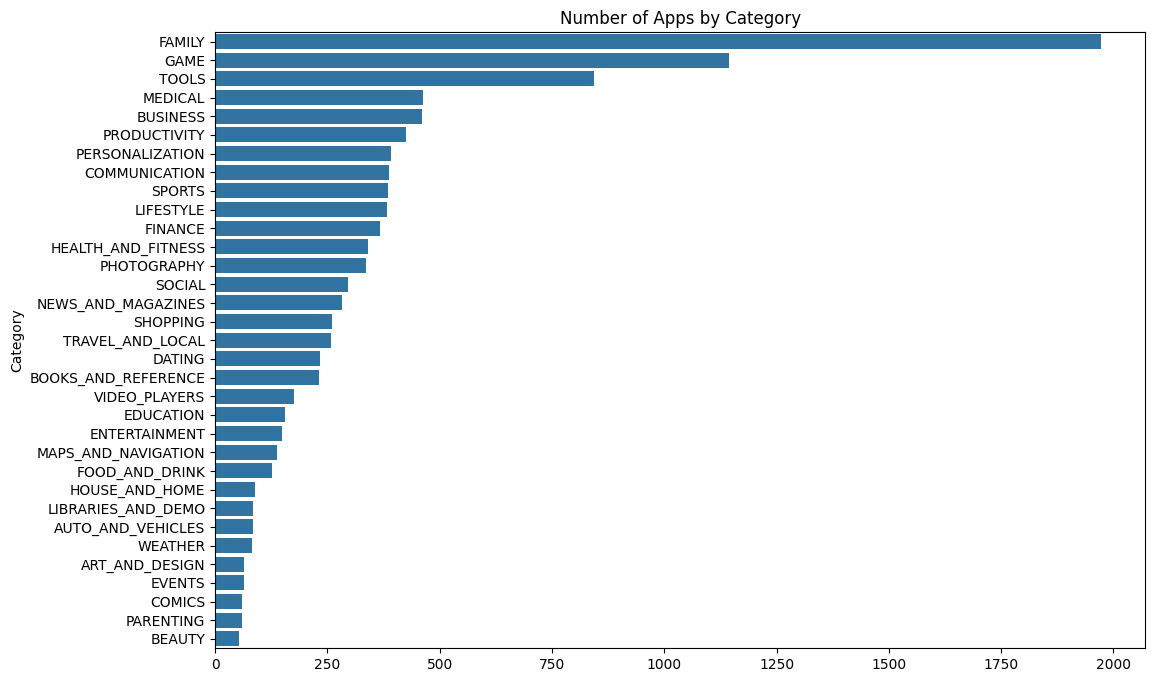

In [38]:
category_count = (
    df["Category"]
    .value_counts()
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=category_count.values,
    y=category_count.index
)

plt.title("Number of Apps by Category")

plt.show()

The ```Family``` category appears highly saturated. Google may consider encouraging developers toward less competitive categories to improve marketplace diversity.

**4. Market Share**


Which categories dominate the marketplace?

In [39]:
category_share = (
    df["Category"]
      .value_counts(normalize=True)
      *100
)

category_share.head()

,proportion
Category,
FAMILY,18.191882
GAME,10.553506
TOOLS,7.776753
MEDICAL,4.271218
BUSINESS,4.243542


**5. User Demand**

Where are users actually downloading apps?

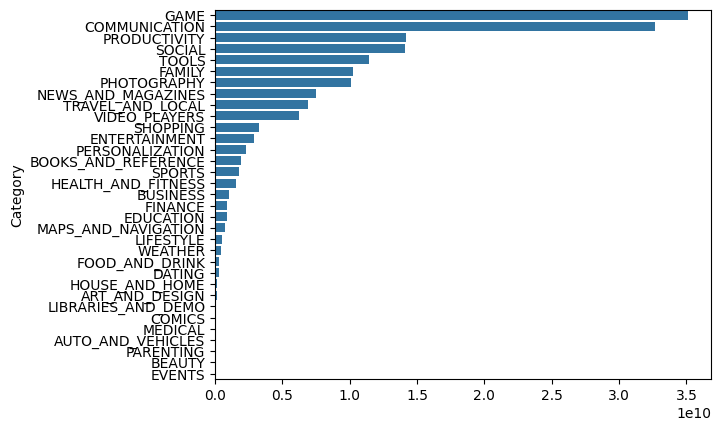

In [40]:
install_summary = (
    df.groupby("Category")["Installs"]
      .sum()
      .sort_values(ascending=False)
)

sns.barplot(x=install_summary.values,
            y=install_summary.index)
plt.show()

People made large installs of ```Game``` Category apps.

**6. Average Rating by Category**

Which categories make users happiest?

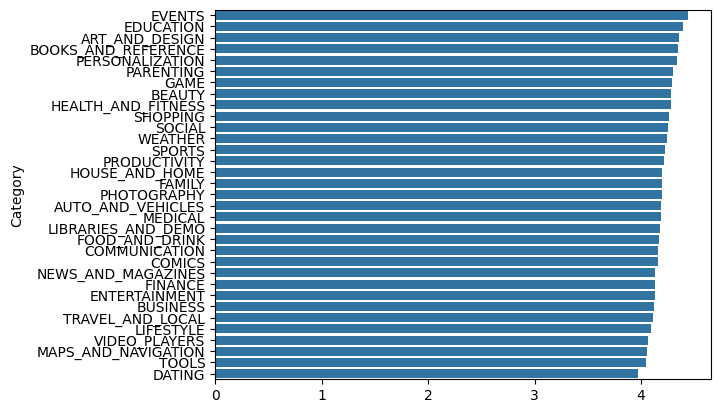

In [41]:
rating_summary = (
    df.groupby("Category")["Rating"]
      .mean()
      .sort_values(ascending=False)
)

sns.barplot(x=rating_summary.values,
            y=rating_summary.index)

plt.show()

Categories such as Events and Education consistently achieve higher average user satisfaction, suggesting stronger alignment with user expectations and potentially higher-quality applications.

**7. Free vs Paid**

Does charging money reduce adoption?

In [42]:
df["Type"].value_counts(normalize=True)*100

,proportion
Type,
Free,92.619245
Paid,7.380755


In [43]:
# Average Installs
df.groupby("Type")["Installs"].mean()

,Installs
Type,
Free,1.669095e+07
Paid,9.119510e+04


In [44]:
# Average ratings
df.groupby("Type")["Rating"].mean()

,Rating
Type,
Free,4.186203
Paid,4.266615


Google Apps user likely give more average ratings to paid Apps than free apps even if the installs of free apps is comparatively higher than that of paid apps.

**8. Size Analysis**

Does application size influence user adoption?

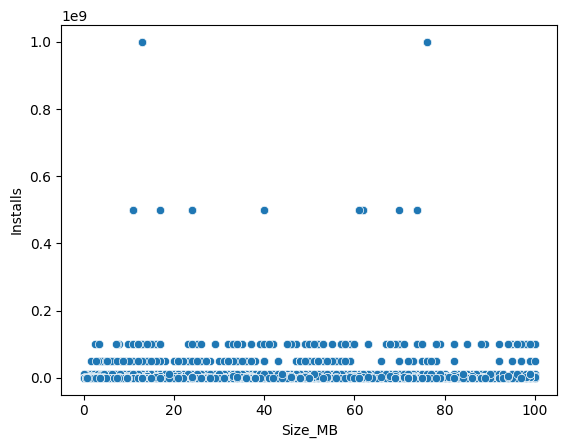

In [45]:
sns.scatterplot(x=df["Size_MB"], y=df["Installs"])
plt.show()

There is no obvious linear relationship between app size and installs.
Since, Install values are extremely skewed, we will visualize size with log of Installs.

<Axes: xlabel='Size_MB', ylabel='Log_Installs'>

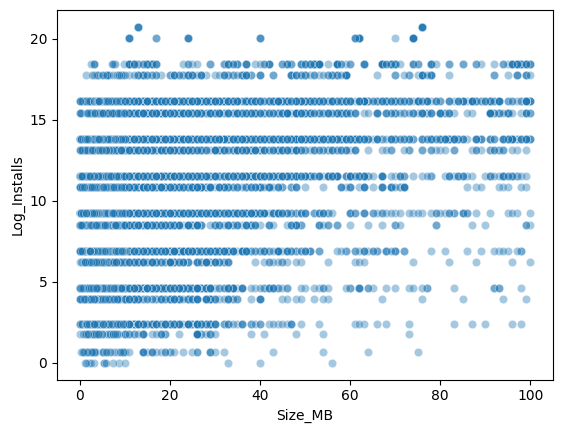

In [46]:
import numpy as np

df["Log_Installs"] = np.log1p(df["Installs"])

sns.scatterplot(
    x="Size_MB",
    y="Log_Installs",
    data=df,
    alpha=0.4
)

Visually it can be said that App size alone does not explain install count as our graph looks like a cloud of points.

But we cannot finally conclude this, as their is no strong evidence. Now, we apply hypothesis and statistical tests.

In [47]:
# Measure the relationship

df[["Size_MB","Log_Installs"]].corr()

,Size_MB,Log_Installs
Size_MB,1.000000,0.334919
Log_Installs,0.334919,1.000000


There is a weak positive linear relationship between application size and install count (after log transformation).

In [48]:
from scipy.stats import spearmanr

corr, p = spearmanr(df["Size_MB"], df["Installs"], nan_policy="omit")

print("Spearman Correlation:", corr)
print("P-value:", p)

Spearman Correlation: 0.34817719695800375
P-value: 6.468178193608623e-259


-> Spearman Correlation=0.348 means even when looking only at rank order, larger applications tend to have slightly higher installs.

Why Spearman?

Because:

- Installs are not normally distributed.
- Relationship may not be linear.
- Spearman is more robust.

-> Hypothesis

**H₀ (Null)** : There is no relationship between app size and installs.

**H₁** : There is a relationship.

Since P-value is approximately equal to zero, and P < 0.05 .
We Reject H₀.
That means, the observed relationship is statistically significant.



*While application size shows a statistically significant positive association with install count (Spearman ρ = 0.348, p < 0.001), the effect size is relatively weak. This suggests that application size contributes only marginally to app popularity. Other factors such as ratings, reviews, category, and brand reputation are likely to have a substantially greater influence on user adoption.*

Games -> Large Size -> High Installs

```Size``` isn't causing installs.

```Category``` may be the hidden factor.

This is called a **confounding variable.**



**9.  Reviews**

Are reviews a proxy for popularity?

In [49]:
df[
    ["Reviews","Installs"]
].corr()

,Reviews,Installs
Reviews,1.000000,0.643122
Installs,0.643122,1.000000


0.643 indicates a strong positive relationship.

This means: Apps with more reviews generally have more installs.

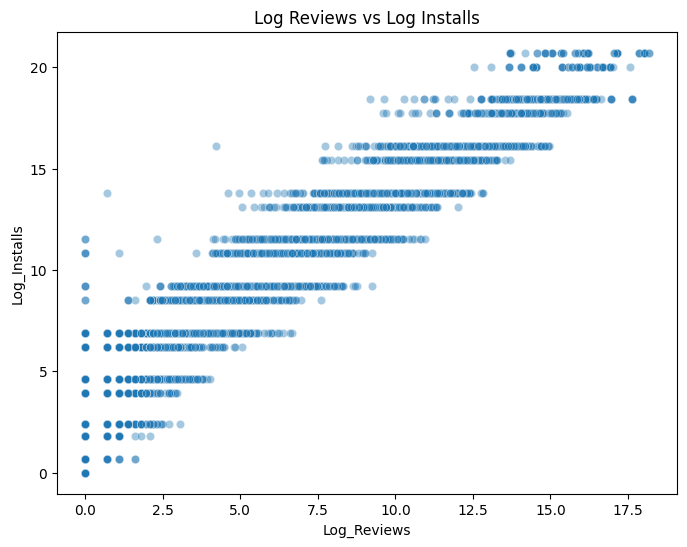

In [50]:
import numpy as np

df["Log_Reviews"] = np.log1p(df["Reviews"])
df["Log_Installs"] = np.log1p(df["Installs"])

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="Log_Reviews",
    y="Log_Installs",
    alpha=0.4
)

plt.title("Log Reviews vs Log Installs")
plt.show()

Review count is much more informative than application size when estimating app popularity. Correlation is not closer to 1.0, Review count explains part of install behavior—not all of it.

In [51]:
from scipy.stats import spearmanr

corr, p = spearmanr(
    df["Log_Reviews"],
    df["Log_Installs"],
    nan_policy="omit"
)

print(corr)
print(p)

0.9712189150469286
0.0


Spearman is also high (>0.6) and p-value < 0.05, have stronger evidence that the relationship is consistent.

**10. Last Updated**

Do regularly updated apps perform better?
**OR** Do recently updated apps have different average ratings than older apps?

In [52]:
df["Year"] = df["Last Updated"].dt.year

df.groupby("Year")["Rating"].mean()

,Rating
Year,
2010,4.200000
2011,3.966667
2012,3.785714
2013,4.073404
2014,4.037895
2015,4.067268
2016,4.041782
2017,4.094793
2018,4.244530


In [53]:
df.groupby("Year")["Installs"].mean()

,Installs
Year,
2010,1.000000e+05
2011,1.160473e+06
2012,5.381619e+05
2013,9.381033e+05
2014,1.291657e+06
2015,9.249270e+05
2016,1.743154e+06
2017,2.180747e+06
2018,2.195282e+07


In [54]:
reference_date = df["Last Updated"].max()

df["Days_Since_Update"] = (
    reference_date - df["Last Updated"]
).dt.days

In [55]:
bins = [0,30,180,365,1000,5000]

labels = [
    "Last Month",
    "6 Months",
    "1 Year",
    "3 Years",
    "Very Old"
]

df["Update_Group"] = pd.cut(
    df["Days_Since_Update"],
    bins=bins,
    labels=labels
)

In [56]:
df.groupby("Update_Group")[
    ["Rating","Installs"]
].mean()

/tmp/ipykernel_1780/3653889959.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("Update_Group")[


,Rating,Installs
Update_Group,,
Last Month,4.285614,3.544033e+07
6 Months,4.200144,8.778002e+06
1 Year,4.117690,3.204863e+06
3 Years,4.073053,1.470411e+06
Very Old,4.046861,9.394484e+05


This signifies that the apps updated most frequently after launch are comparatively receive more installs and ratings.

- Null Hypothesis: The average ratings are the same across all update groups.
- Alternative Hypothesis (H₁): At least one update group has a different average rating.

In [57]:
# Use ANOVA
from scipy.stats import f_oneway

groups = [
    g["Rating"].dropna()
    for _, g in df.groupby("Update_Group")
]

f,p = f_oneway(*groups)

print(f)
print(p)

67.87210223205985
1.0227291822835279e-56


/tmp/ipykernel_1780/1553923497.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for _, g in df.groupby("Update_Group")


- F = 67.87 is a very large F-value.

It suggests: Ratings differ substantially between at least some update groups.

- P-value is much smaller than 0.05, thus we reject null hypothesis.

Statistical analysis indicates that average application ratings differ significantly across update recency groups (F = 67.87, p < 0.001). This provides strong evidence that the recency of app updates is associated with differences in user satisfaction.

Google should reward actively maintained apps in search rankings. Since, the available dataset only contains the most recent update date for each application. Therefore, update frequency cannot be directly measured. The analysis can only evaluate update recency, not maintenance frequency.

**11. Content Rating**


Which audience generates the highest engagement?

<Axes: xlabel='Content Rating', ylabel='Category'>

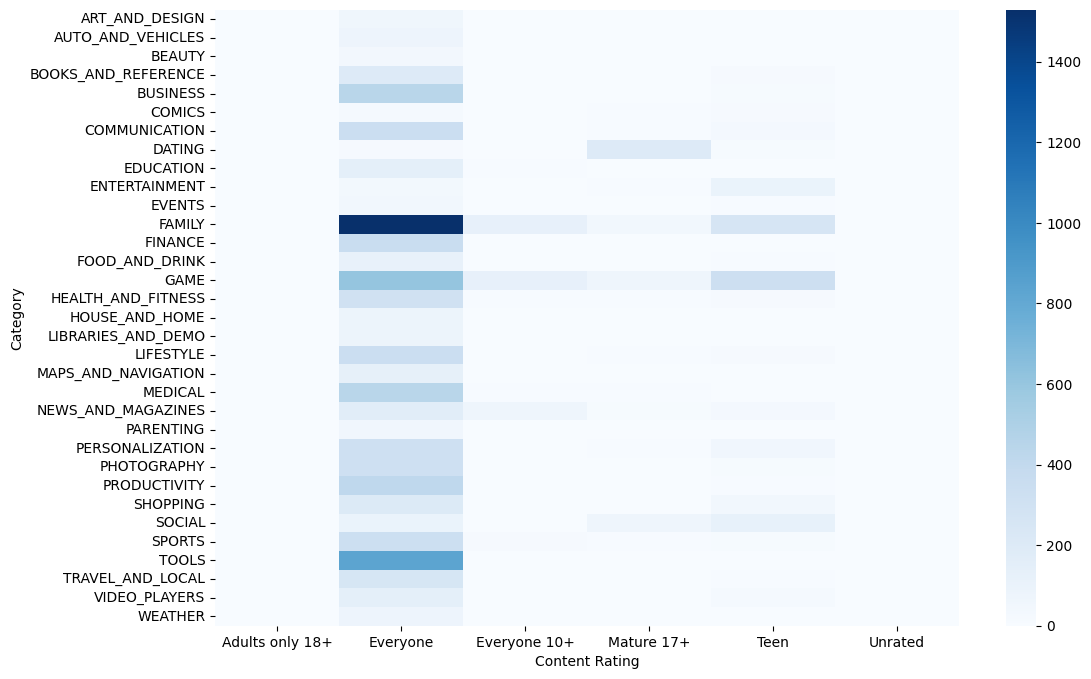

In [58]:
plt.figure(figsize=(12,8))

sns.heatmap(
    pd.crosstab(
        df["Category"],
        df["Content Rating"]
    ),
    cmap="Blues"
)

This heatmap suggests that Category and Content Rating are highly dependent variables.

In [59]:
df.groupby("Content Rating")["Rating"].mean()

,Rating
Content Rating,
Adults only 18+,4.300000
Everyone,4.186375
Everyone 10+,4.257179
Mature 17+,4.123427
Teen,4.233487
Unrated,4.100000


In [60]:
df.groupby("Content Rating")["Installs"].mean()

,Installs
Content Rating,
Adults only 18+,6.666667e+05
Everyone,1.310037e+07
Everyone 10+,3.196590e+07
Mature 17+,1.107112e+07
Teen,2.873870e+07
Unrated,2.525000e+04


Content rating column contains mixed type of categories which do not signifies the distribution of app purchase among differnt groups.

# Market Opportunity Analysis

In [61]:
category_analysis = (
    df.groupby("Category")
      .agg(
          Total_Apps=("App", "count"),
          Avg_Rating=("Rating", "mean"),
          Median_Rating=("Rating", "median"),
          Avg_Reviews=("Reviews", "mean"),
          Avg_Installs=("Installs", "mean"),
          Median_Installs=("Installs", "median"),
          Paid_App_Count=("Type", lambda x: (x=="Paid").sum()),
          Free_App_Count=("Type", lambda x: (x=="Free").sum()),
          Avg_Size=("Size_MB", "mean"),
          Avg_Price=("Price", "mean")
      )
      .round(2)
)

category_analysis

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price
Category,,,,,,,,,,
ART_AND_DESIGN,65,4.36,4.4,26376.00,1912893.85,100000.0,3,62,12.37,0.09
AUTO_AND_VEHICLES,85,4.19,4.3,13690.19,625061.31,100000.0,3,82,20.04,0.16
BEAUTY,53,4.28,4.3,7476.23,513151.89,50000.0,0,53,13.80,0.00
BOOKS_AND_REFERENCE,231,4.35,4.5,95060.90,8318050.11,10000.0,28,203,13.31,0.52
BUSINESS,460,4.12,4.3,30335.98,2178075.79,1000.0,14,446,14.47,0.40
COMICS,60,4.16,4.4,56387.93,934769.17,100000.0,0,60,13.48,0.00
COMMUNICATION,387,4.16,4.3,2107137.62,84359886.95,1000000.0,27,360,11.77,0.21
DATING,234,3.97,4.1,31159.31,1129533.36,100000.0,7,227,16.63,0.13
EDUCATION,156,4.39,4.4,253819.14,5586230.77,1000000.0,4,152,20.79,0.12


In [62]:
# Which categories are overcrowded?

category_analysis.sort_values(
    "Total_Apps",
    ascending=False
).head()

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price
Category,,,,,,,,,,
FAMILY,1972,4.19,4.3,208025.52,5201959.18,100000.0,191,1780,28.32,1.23
GAME,1144,4.29,4.4,1385858.70,30669601.76,1000000.0,83,1061,44.37,0.25
TOOLS,843,4.05,4.2,324062.92,13585731.81,50000.0,78,765,8.77,0.32
MEDICAL,463,4.19,4.3,3425.43,115026.86,1000.0,109,354,19.63,3.11
BUSINESS,460,4.12,4.3,30335.98,2178075.79,1000.0,14,446,14.47,0.40


In [63]:
# Which categories have the highest demand?

category_analysis.sort_values(
    "Avg_Installs",
    ascending=False
).head()

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price
Category,,,,,,,,,,
COMMUNICATION,387,4.16,4.3,2107137.62,84359886.95,1000000.0,27,360,11.77,0.21
SOCIAL,295,4.26,4.3,2105903.13,47694467.46,1000000.0,3,292,17.68,0.05
VIDEO_PLAYERS,175,4.06,4.2,630743.93,35554301.26,1000000.0,4,171,16.08,0.06
PRODUCTIVITY,424,4.21,4.3,269143.81,33434177.76,300000.0,28,396,12.98,0.59
GAME,1144,4.29,4.4,1385858.70,30669601.76,1000000.0,83,1061,44.37,0.25


In [64]:
# Which categories have strong demand but relatively little competition?

category_analysis["Opportunity_Index"] = (
    category_analysis["Median_Installs"] /
    category_analysis["Total_Apps"]
)

category_analysis.sort_values(
    "Opportunity_Index",
    ascending=False
).head()

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price,Opportunity_Index
Category,,,,,,,,,,,
ENTERTAINMENT,149,4.13,4.2,397168.82,19256107.38,5000000.0,2,147,21.85,0.05,33557.046980
PHOTOGRAPHY,335,4.19,4.3,637363.13,30114172.10,5000000.0,22,313,17.37,0.40,14925.373134
WEATHER,82,4.24,4.3,178106.52,5196347.80,1000000.0,8,74,13.12,0.40,12195.121951
EDUCATION,156,4.39,4.4,253819.14,5586230.77,1000000.0,4,152,20.79,0.12,6410.256410
VIDEO_PLAYERS,175,4.06,4.2,630743.93,35554301.26,1000000.0,4,171,16.08,0.06,5714.285714


In [65]:
# Competition score

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

category_analysis["Competition_Score"] = scaler.fit_transform(
    category_analysis[["Total_Apps"]]
)

category_analysis.sort_values(
    "Competition_Score",
    ascending=False
).head()

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price,Opportunity_Index,Competition_Score
Category,,,,,,,,,,,,
FAMILY,1972,4.19,4.3,208025.52,5201959.18,100000.0,191,1780,28.32,1.23,50.709939,1.000000
GAME,1144,4.29,4.4,1385858.70,30669601.76,1000000.0,83,1061,44.37,0.25,874.125874,0.568525
TOOLS,843,4.05,4.2,324062.92,13585731.81,50000.0,78,765,8.77,0.32,59.311981,0.411673
MEDICAL,463,4.19,4.3,3425.43,115026.86,1000.0,109,354,19.63,3.11,2.159827,0.213653
BUSINESS,460,4.12,4.3,30335.98,2178075.79,1000.0,14,446,14.47,0.40,2.173913,0.212090


In [66]:
# Demand score

category_analysis["Demand_Score"] = scaler.fit_transform(
    category_analysis[["Median_Installs"]]
)

category_analysis.sort_values(
    "Demand_Score",
    ascending=False
).head()

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price,Opportunity_Index,Competition_Score,Demand_Score
Category,,,,,,,,,,,,,
ENTERTAINMENT,149,4.13,4.2,397168.82,19256107.38,5000000.0,2,147,21.85,0.05,33557.046980,0.050026,1.00000
PHOTOGRAPHY,335,4.19,4.3,637363.13,30114172.10,5000000.0,22,313,17.37,0.40,14925.373134,0.146952,1.00000
SHOPPING,260,4.26,4.3,442466.24,12491726.10,1000000.0,2,258,16.18,0.02,3846.153846,0.107869,0.19984
GAME,1144,4.29,4.4,1385858.70,30669601.76,1000000.0,83,1061,44.37,0.25,874.125874,0.568525,0.19984
EDUCATION,156,4.39,4.4,253819.14,5586230.77,1000000.0,4,152,20.79,0.12,6410.256410,0.053674,0.19984


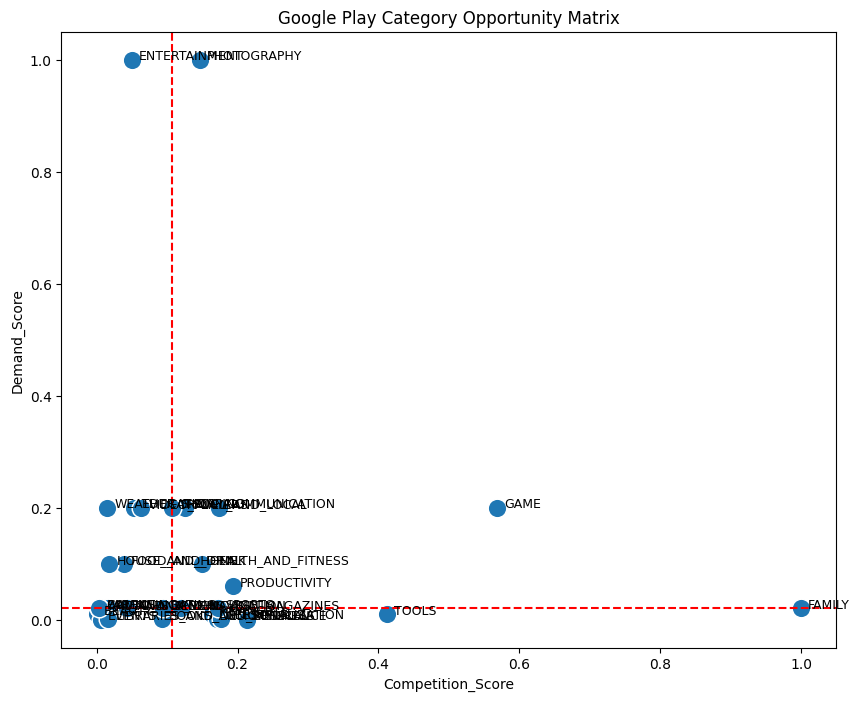

In [67]:
# Where does a typical developer have the best chance of succeeding?

plt.figure(figsize=(10,8))

sns.scatterplot(
    data=category_analysis,
    x="Competition_Score",
    y="Demand_Score",
    s=180
)

for category in category_analysis.index:
    plt.text(
        category_analysis.loc[category,"Competition_Score"]+0.01,
        category_analysis.loc[category,"Demand_Score"],
        category,
        fontsize=9
    )

plt.axvline(
    category_analysis["Competition_Score"].median(),
    linestyle="--",
    color="red"
)

plt.axhline(
    category_analysis["Demand_Score"].median(),
    linestyle="--",
    color="red"
)

plt.title("Google Play Category Opportunity Matrix")

plt.show()

1. Google should encourage development in:

- Entertainment
- Photography

These categories show healthy user demand without excessive saturation.

2. Family, Game, and Tools appear saturated.

Google could:

- Improve recommendation diversity
- Promote high-quality niche apps
- Reward actively maintained apps

rather than allowing rankings to be dominated by already popular apps.

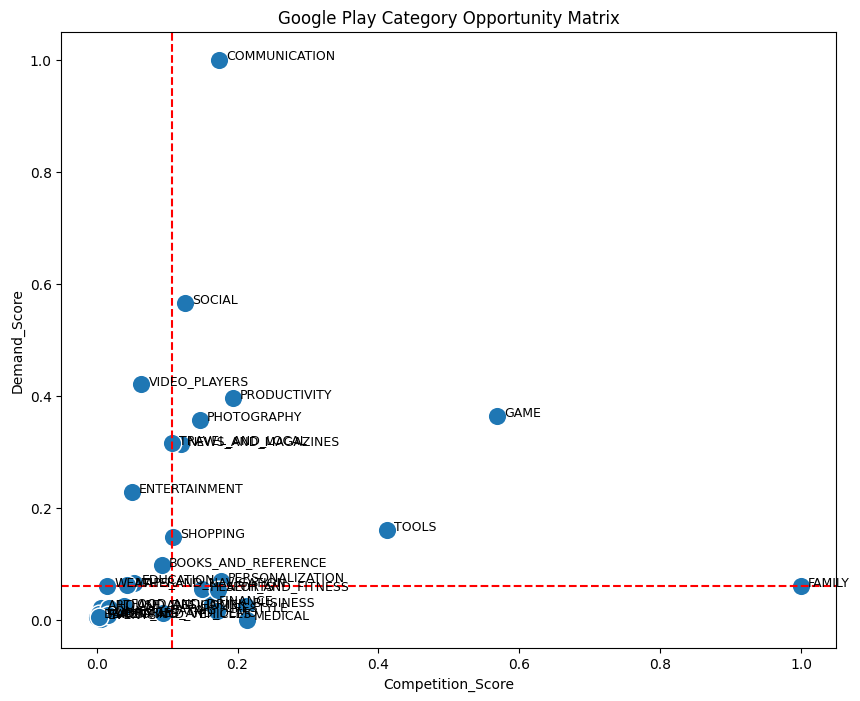

In [68]:
# Where is the largest market opportunity?

# Demand score

category_analysis["Demand_Score"] = scaler.fit_transform(
    category_analysis[["Avg_Installs"]]
)

category_analysis.sort_values(
    "Demand_Score",
    ascending=False
).head()

# Where does a typical developer have the best chance of succeeding?

plt.figure(figsize=(10,8))

sns.scatterplot(
    data=category_analysis,
    x="Competition_Score",
    y="Demand_Score",
    s=180
)

for category in category_analysis.index:
    plt.text(
        category_analysis.loc[category,"Competition_Score"]+0.01,
        category_analysis.loc[category,"Demand_Score"],
        category,
        fontsize=9
    )

plt.axvline(
    category_analysis["Competition_Score"].median(),
    linestyle="--",
    color="red"
)

plt.axhline(
    category_analysis["Demand_Score"].median(),
    linestyle="--",
    color="red"
)

plt.title("Google Play Category Opportunity Matrix")

plt.show()

- Communication, Social, Photography, and Video Players offer attractive opportunities because they combine relatively high average installs with manageable competition.
- Games represent a high-risk, high-reward market where strong user demand is offset by intense competition.
- Family and Tools appear highly saturated, making it difficult for the average new app to gain visibility.
- Most remaining categories are niche markets with both lower competition and lower average installs.

In [69]:
# Which categories produce high-quality apps?

category_analysis.sort_values(
    "Avg_Rating",
    ascending=False
).head()

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price,Opportunity_Index,Competition_Score,Demand_Score
Category,,,,,,,,,,,,,
EVENTS,64,4.44,4.5,2515.91,249580.64,1000.0,1,63,13.96,1.72,15.625000,0.005732,0.001597
EDUCATION,156,4.39,4.4,253819.14,5586230.77,1000000.0,4,152,20.79,0.12,6410.256410,0.053674,0.064944
ART_AND_DESIGN,65,4.36,4.4,26376.00,1912893.85,100000.0,3,62,12.37,0.09,1538.461538,0.006253,0.021341
BOOKS_AND_REFERENCE,231,4.35,4.5,95060.90,8318050.11,10000.0,28,203,13.31,0.52,43.290043,0.092757,0.097371
PERSONALIZATION,392,4.34,4.4,227923.83,5932384.65,10000.0,83,309,11.30,0.39,25.510204,0.176655,0.069053


In [70]:
# Which categories successfully sell paid apps?

category_analysis.sort_values(
    "Avg_Price",
    ascending=False
).head()

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price,Opportunity_Index,Competition_Score,Demand_Score
Category,,,,,,,,,,,,,
FINANCE,366,4.13,4.3,47952.81,2395215.12,50000.0,17,349,17.93,7.93,136.612022,0.163106,0.027066
LIFESTYLE,382,4.09,4.2,33724.57,1407443.82,10000.0,19,363,14.75,6.18,26.178010,0.171443,0.015341
MEDICAL,463,4.19,4.3,3425.43,115026.86,1000.0,109,354,19.63,3.11,2.159827,0.213653,0.000000
EVENTS,64,4.44,4.5,2515.91,249580.64,1000.0,1,63,13.96,1.72,15.625000,0.005732,0.001597
FAMILY,1972,4.19,4.3,208025.52,5201959.18,100000.0,191,1780,28.32,1.23,50.709939,1.000000,0.060383


In [71]:
#  Which categories deserve investment?

category_analysis["Market_Health"] = (
      0.4*category_analysis["Demand_Score"]
    + 0.3*(category_analysis["Avg_Rating"]/5)
    - 0.3*category_analysis["Competition_Score"]
)

category_analysis.sort_values(
    "Market_Health",
    ascending=False
).head()

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price,Opportunity_Index,Competition_Score,Demand_Score,Market_Health
Category,,,,,,,,,,,,,,
COMMUNICATION,387,4.16,4.3,2107137.62,84359886.95,1000000.0,27,360,11.77,0.21,2583.979328,0.174049,1.000000,0.597385
SOCIAL,295,4.26,4.3,2105903.13,47694467.46,1000000.0,3,292,17.68,0.05,3389.830508,0.126107,0.564776,0.443678
VIDEO_PLAYERS,175,4.06,4.2,630743.93,35554301.26,1000000.0,4,171,16.08,0.06,5714.285714,0.063575,0.420670,0.392796
PRODUCTIVITY,424,4.21,4.3,269143.81,33434177.76,300000.0,28,396,12.98,0.59,707.547170,0.193330,0.395504,0.352803
PHOTOGRAPHY,335,4.19,4.3,637363.13,30114172.10,5000000.0,22,313,17.37,0.40,14925.373134,0.146952,0.356095,0.349752


Recently, we apply heuristic coefficents. But how much confidence we have in this result is clearly being determined by collecting evidences.

In [72]:
import pandas as pd
import numpy as np

model_df = df.copy()

# Log transform target
model_df["Log_Installs"] = np.log1p(model_df["Installs"])

# Binary encoding
model_df["Type"] = model_df["Type"].map({
    "Free":0,
    "Paid":1
})

# Select useful features
model_df = model_df[
    [
        "Log_Installs",
        "Rating",
        "Reviews",
        "Size_MB",
        "Price",
        "Type",
        "Category"
    ]
]

# Remove missing values
model_df = model_df.dropna()

# One-hot encode Category
model_df = pd.get_dummies(
    model_df,
    columns=["Category"],
    drop_first=True,
    dtype=int
)

model_df.head()

,Log_Installs,Rating,Reviews,Size_MB,Price,Type,Category_AUTO_AND_VEHICLES,Category_BEAUTY,Category_BOOKS_AND_REFERENCE,Category_BUSINESS,...,Category_PERSONALIZATION,Category_PHOTOGRAPHY,Category_PRODUCTIVITY,Category_SHOPPING,Category_SOCIAL,Category_SPORTS,Category_TOOLS,Category_TRAVEL_AND_LOCAL,Category_VIDEO_PLAYERS,Category_WEATHER
0,9.210440,4.1,159.0,19.0,0.0,0.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,13.122365,3.9,967.0,14.0,0.0,0.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,15.424949,4.7,87510.0,8.7,0.0,0.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,17.727534,4.5,215644.0,25.0,0.0,0.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,11.512935,4.3,967.0,2.8,0.0,0.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [73]:
from sklearn.preprocessing import StandardScaler

numeric_cols = [
    "Rating",
    "Reviews",
    "Size_MB",
    "Price"
]

scaler = StandardScaler()

model_df[numeric_cols] = scaler.fit_transform(
    model_df[numeric_cols]
)

In [74]:
# EVIDENCE 1: Multiple Linear Regression

import statsmodels.api as sm

X = model_df.drop(columns="Log_Installs")

y = model_df["Log_Installs"]

X = sm.add_constant(X)

ols_model = sm.OLS(y, X).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:           Log_Installs   R-squared:                       0.288
Model:                            OLS   Adj. R-squared:                  0.284
Method:                 Least Squares   F-statistic:                     83.94
Date:                Mon, 03 Aug 2026   Prob (F-statistic):               0.00
Time:                        08:56:56   Log-Likelihood:                -19763.
No. Observations:                7729   AIC:                         3.960e+04
Df Residuals:                    7691   BIC:                         3.987e+04
Df Model:                          37                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

In [75]:
coef_table = pd.DataFrame({
    "Feature":ols_model.params.index,
    "Coefficient":ols_model.params.values,
    "P-value":ols_model.pvalues.values
})

coef_table.sort_values(
    "Coefficient",
    ascending=False
).head()

,Feature,Coefficient,P-value
0,const,11.871416,1.055941e-176
14,Category_ENTERTAINMENT,2.850940,5.641978e-08
13,Category_EDUCATION,1.871776,2.118914e-04
29,Category_PHOTOGRAPHY,1.801291,7.801522e-05
37,Category_WEATHER,1.787168,2.825861e-03


In [76]:
# Evidence 2: Check Multicollinearity (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame()

vif["Feature"] = X.columns

vif["VIF"] = [
    variance_inflation_factor(
        X.values,
        i
    )
    for i in range(X.shape[1])
]

vif.sort_values("VIF", ascending=False).head()

,Feature,VIF
0,const,131.427441
16,Category_FAMILY,22.609559
19,Category_GAME,15.610953
34,Category_TOOLS,10.820989
25,Category_MEDICAL,6.251780


In [77]:
# EVIDENCE 3: RandomForest Feature Importance

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

rf.fit(
    X.drop(columns="const"),
    y
)

importance = pd.DataFrame({

    "Feature":X.drop(columns="const").columns,

    "Importance":rf.feature_importances_

})

importance.sort_values(
    "Importance",
    ascending=False
).head()

,Feature,Importance
1,Reviews,0.932581
0,Rating,0.017842
2,Size_MB,0.016908
3,Price,0.007066
4,Type,0.005056


In [78]:
# Evidence 4: Spearman Correlation

from scipy.stats import spearmanr
import pandas as pd

features = [
    "Rating",
    "Reviews",
    "Size_MB",
    "Price"
]

results = []

for feature in features:

    corr, p = spearmanr(
        df[feature],
        df["Installs"],
        nan_policy="omit"
    )
    results.append({
        "Feature": feature,
        "Spearman_Correlation": corr,
        "P_Value": p
    })

spearman_results = (
    pd.DataFrame(results)
      .sort_values(
          "Spearman_Correlation",
          ascending=False
      )
)

spearman_results

,Feature,Spearman_Correlation,P_Value
1,Reviews,0.971219,0.000000e+00
2,Size_MB,0.348177,6.468178e-259
0,Rating,0.069546,1.608658e-11
3,Price,-0.242958,2.036377e-145


In [82]:
# Improvized health score based on above evidence

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

category_analysis[[
        "Demand",
        "Reviews",
        "Rating",
        "Competition"
]] = scaler.fit_transform(

category_analysis[[
        "Median_Installs",
        "Avg_Reviews",
        "Avg_Rating",
        "Total_Apps"
        ]]
)

In [83]:
category_analysis["Market_Health"] = (

0.45*category_analysis["Reviews"] +

0.30*category_analysis["Demand"] +

0.15*category_analysis["Rating"] -

0.10*category_analysis["Competition"]
)

In [84]:
category_analysis.sort_values(
    "Market_Health",
    ascending=False
).head()

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price,Opportunity_Index,Competition_Score,Demand_Score,Market_Health,Demand,Reviews,Rating,Competition
Category,,,,,,,,,,,,,,,,,,
SOCIAL,295,4.26,4.3,2105903.13,47694467.46,1000000.0,3,292,17.68,0.05,3389.830508,0.126107,0.564776,0.589630,0.19984,0.999413,0.617021,0.126107
COMMUNICATION,387,4.16,4.3,2107137.62,84359886.95,1000000.0,27,360,11.77,0.21,2583.979328,0.174049,1.000000,0.553185,0.19984,1.000000,0.404255,0.174049
PHOTOGRAPHY,335,4.19,4.3,637363.13,30114172.10,5000000.0,22,313,17.37,0.40,14925.373134,0.146952,0.356095,0.491258,1.00000,0.301644,0.468085,0.146952
ENTERTAINMENT,149,4.13,4.2,397168.82,19256107.38,5000000.0,2,147,21.85,0.05,33557.046980,0.050026,0.227208,0.430444,1.00000,0.187517,0.340426,0.050026
GAME,1144,4.29,4.4,1385858.70,30669601.76,1000000.0,83,1061,44.37,0.25,874.125874,0.568525,0.362688,0.401007,0.19984,0.657288,0.680851,0.568525


We now become confident about this result because even after changing coefficient the categories rarely swap from their position. And this is called Sensitivity Analysis. This reveals category suceess index.